# Social Interactions: Do the Accounts I Engage With Ebb and Flow?
**Name:** Jason Bogovich  
**Date:** Wed, Sep. 23rd 2026

### Who or what is the source of this data?
The source is not a single source. The reactions were initiated by me, but they were influenced by my network, advertisers, and Facebook's algorithm itself. What I was shown, and therefore what I could react to, was chosen partly from my own past activity. So in some way there is an algorithmic feedback loop between my perceptions, my activity, and my interests.

### Why was this data created, and what purposes can it serve?
Facebook records every reaction because the product runs on them: they drive the reaction counts on posts, rank my feed, and target ads. The *download* of that data has a different history. In the late 2000s, RSS and data portability were popular ideas, and the tech consensus was that Facebook threatened the open web because it was a closed system, a "walled garden." Tim Berners-Lee made this argument in *Scientific American* in 2010 ("Long Live the Web"), the same year Facebook launched its download tool. I read the tool partly as a way to take the wind out of that criticism: in effect, *"See, it's not the end of the internet. Here, download your file and take it to your app."* In 2018, the EU's GDPR made data portability a legal right. As the [EFF](https://www.eff.org/deeplinks/2018/09/what-we-mean-when-we-say-data-portability) points out, portability is not only about moving to a rival service; it is also about analyzing your data to understand your relationship with a service.

In my view, the export assumed users could do something with raw JSON. In practice, most people want turnkey tools, and until AI coding assistants became widely available, analyzing this data required programming skills most users don't have. This report shows why: four files, two formats, duplicates, and writing a regular expression was required before a single count was possible. None of this would have been practical for the everyday person without AI. RegEx can feel like reading machine code; it can be a pain. The data is also useful. It's useful for introspection: seeing my past self always feels a little embarrassing, like hearing a recording of my own voice. It's also useful for cringing at the personal information I share with advertisers and technology companies.

### In what ways may this data be reliable?
* **Data is logged automatically, at the moment of interaction.** 
* **A complete record, not a sample.** The export should contain every reaction in its one-year window.
* **Facebook has a business reason to get it right.** Its feed and its ads depend on this data being accurate.
* **It can be cross-checked.** The export contains the same reactions in two different formats, and they agree to the second on 99% of records (section 5b).

### In what ways may this data be unreliable?
* **The structure is inconsistent.** One export holds two formats that name reactions differently (`SORRY` vs `Sad`) and garble accented names. A naive parse either drops half the data (at first I thought almost half of my reactions were missing) or counts about 4,600 reactions twice.
* **The two copies do not fully agree.** 398 reactions appear in only one format, and 32 are credited to different people.
* **Names are not IDs.** Accounts are identified only by display name, and some titles name no one at all.
* **It records behaviour inside a system, not pure preference.** The algorithm decided what I saw, so the data shows what I reacted to *among the things I was shown*.


## 1. Setup

`DATA_DIR` is the folder holding the JSON files (`"."` = the same folder as this notebook). `fix_text()` repairs a known bug in Facebook exports: accented letters and emoji are saved garbled (UTF-8 bytes read as Latin-1), so a name like *Zoë* arrives as *ZoÃ«*.

In [127]:
import json
import glob
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = "."
SECOND_FILE = os.path.join(DATA_DIR, "comments.json")

def fix_text(s):
    """Undo Facebook's garbled encoding of accented letters and emoji."""
    if not isinstance(s, str):
        return s
    try:
        return s.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

## 2. Loading the reactions data

Facebook split my reactions across four files. Counting each file's records by structure shows that the export contains **two different record formats, one per file**. To avoid displaying other people's names before they are pseudonymized (section 5c), the examples below show each format with its text masked.

In [128]:
files = sorted(glob.glob(os.path.join(DATA_DIR, "likes_and_reactions*.json")))

records = []
for path in files:
    with open(path, encoding="utf-8") as f:
        recs = json.load(f)
    n_old = sum(1 for r in recs if "data" in r)
    n_new = sum(1 for r in recs if "label_values" in r)
    print(f"{os.path.basename(path):28} {len(recs):>5} records   old format: {n_old:>5}   new format: {n_new:>5}")
    records.extend(recs)
print(len(records), "records in total")

def mask(x):
    """Show a record's structure without the names and text inside it."""
    if isinstance(x, dict):
        return {k: (v if k == "label" else mask(v)) for k, v in x.items()}
    if isinstance(x, list):
        return [mask(i) for i in x]
    return "<text>" if isinstance(x, str) else x

print("\nOld format:", json.dumps(mask(next(r for r in records if "data" in r))))
print("\nNew format:", json.dumps(mask(next(r for r in records if "label_values" in r))))

likes_and_reactions.json      4628 records   old format:     0   new format:  4628
likes_and_reactions_1.json    2500 records   old format:  2500   new format:     0
likes_and_reactions_2.json    2500 records   old format:  2500   new format:     0
likes_and_reactions_3.json      39 records   old format:    39   new format:     0
9667 records in total

Old format: {"timestamp": 1756856224, "data": [{"reaction": {"reaction": "<text>", "actor": "<text>"}}], "title": "<text>"}

New format: {"timestamp": 1788371146, "media": [], "label_values": [{"label": "Reaction", "value": "<text>"}, {"label": "URL", "value": "<text>", "href": "<text>"}, {"label": "Title", "value": "<text>"}, {"label": "Name", "value": "<text>"}], "fbid": "<text>"}


The file without a number holds only the **new format** (4,628 records of labeled fields); the three numbered files hold only the **old format** (5,039 records, where the account is written into a sentence). One export containing two structures for the same kind of data suggests Facebook changed how it stores reactions while its download tool still writes out the older log. Section 5b tests whether the two formats hold the same reactions or different ones.

## 3. Converting to a tidy DataFrame

One row per reaction, one column per variable. The loop reads both formats into the same columns (a loop rather than `json_normalize`, because the two formats nest their fields differently):

* **new format:** the reaction and the account are labeled fields. When the reaction was inside a group, the account is nested under *Author* or *Owner*.
* **old format:** the account exists only inside the `title` sentence, so it is filled in from the title in section 5.

In [129]:
def find_names(items):
    """Collect (section, name) pairs from the nested label_values structure."""
    found = []
    for it in items:
        if it.get("label") == "Name":
            found.append(("", it.get("value")))
        for sub in it.get("dict", []):
            for inner in sub.get("dict", []):
                if inner.get("label") == "Name":
                    found.append((it.get("title", ""), inner.get("value")))
    return found

rows = []
for r in records:
    if "label_values" in r:                                   # new format
        lv = r["label_values"]
        names = dict(reversed(find_names(lv)))                # first name per section wins
        rows.append({"format": "new",
                     "reaction": next((i.get("value") for i in lv if i.get("label") == "Reaction"), None),
                     "account": names.get("") or names.get("Author") or names.get("Owner"),
                     "timestamp": r.get("timestamp"),
                     "title": None})
    else:                                                     # old format
        for item in r["data"]:
            rows.append({"format": "old",
                         "reaction": item["reaction"].get("reaction"),
                         "account": None,
                         "timestamp": r.get("timestamp"),
                         "title": r.get("title")})

df = pd.DataFrame(rows)
df["account"] = df["account"].map(fix_text)
df["title"] = df["title"].map(fix_text)
print(len(df), "rows")

# How does each format name the reactions?
pd.crosstab(df["reaction"], df["format"])

9667 rows


format,new,old
reaction,,
,0,2
ANGER,0,30
Angry,28,0
HAHA,0,765
Haha,695,0
LIKE,0,3973
LOVE,0,153
Like,3650,0
Love,146,0


The two formats use **different names for the same reactions**: the old format says `SORRY` and `ANGER`, the new format says `Sad` and `Angry` (and title case throughout). Two old records have an empty reaction. The cell below puts both on a single vocabulary; without this step the formats could not be compared in section 5b.

In [130]:
df["reaction"] = df["reaction"].str.upper().replace({"SORRY": "SAD", "ANGER": "ANGRY"})
df.loc[df["reaction"] == "", "reaction"] = None
print("Reaction names now:", sorted(df["reaction"].dropna().unique()))

Reaction names now: ['ANGRY', 'HAHA', 'LIKE', 'LOVE', 'SAD', 'WOW']


## 4. Timestamp column

The raw `timestamp` is Unix time (seconds, UTC); the new `datetime` column makes it readable.

In [131]:
df["datetime"] = pd.to_datetime(df["timestamp"], unit="s")
df[["format", "reaction", "timestamp", "datetime"]].head()

,format,reaction,timestamp,datetime
0,new,LIKE,1788371146,2026-09-02 17:45:46
1,new,HAHA,1788371084,2026-09-02 17:44:44
2,new,HAHA,1788360649,2026-09-02 14:50:49
3,new,LIKE,1788355813,2026-09-02 13:30:13
4,new,LIKE,1788355764,2026-09-02 13:29:24


## 5. Wrangling the accounts

### 5a. Deriving the account from the old-format title

An old-format title reads like *"Jason Bogovich liked Jane Doe's comment."* The regular expression captures everything between `liked` / `reacted to` and the final `'s` (greedy, so a name with its own apostrophe, such as O'Brien, stays whole), plus the word after it (post, comment, photo...).

In [132]:
extracted = df["title"].str.extract(r"(?:liked|reacted to) (.+)'s (\w+)\.?$")
is_old = df["format"] == "old"
df.loc[is_old, "account"] = extracted.loc[is_old, 0]
df["content_type"] = extracted[1]

no_name = is_old & df["account"].isna()
print(f"{no_name.sum()} of {is_old.sum()} old-format titles name no account:")
df.loc[no_name, "title"].value_counts()

161 of 5039 old-format titles name no account:


title
Jason Bogovich liked a post.                  69
Jason Bogovich liked a comment.               43
Jason Bogovich reacted to a comment.          24
Jason Bogovich reacted to a post.             15
Jason Bogovich liked his own post.             5
Jason Bogovich reacted to his own comment.     3
Jason Bogovich reacted to his own post.        2
Name: count, dtype: int64

These 161 titles (3% of old records) name no account: reactions to my own posts, or to content whose author the export does not name (possibly deleted posts or accounts). They stay in the data but drop out of the per-account counts in section 6.

### 5b. Are the two formats the same reactions?

Both formats cover the same dates, which suggests they record the same reactions twice. The cell below tests this by matching each new-format record to the old records on the exact second, the reaction, and the account.

In [133]:
old = df[df["format"] == "old"]
new = df[df["format"] == "new"]
for name, part in [("old", old), ("new", new)]:
    print(f"{name} format: {len(part):>5} rows, {part['datetime'].min()} to {part['datetime'].max()}")

key = ["timestamp", "reaction", "account"]
exact = new.merge(old[key].drop_duplicates(), on=key, how="left", indicator=True)["_merge"] == "both"

pd.Series({
    "new-format reactions": len(new),
    "  ...whose exact second also appears in the old files": new["timestamp"].isin(old["timestamp"]).sum(),
    "  ...that also match the old record's reaction and account": exact.sum(),
    "old-format reactions whose second is missing from the new file": (~old["timestamp"].isin(new["timestamp"])).sum(),
}, name="count").to_frame()

old format:  5039 rows, 2025-09-02 23:37:04 to 2026-09-02 17:45:49
new format:  4628 rows, 2025-09-02 23:37:04 to 2026-09-02 17:45:46


,count
new-format reactions,4628
...whose exact second also appears in the old files,4628
...that also match the old record's reaction and account,4596
old-format reactions whose second is missing from the new file,398


**The new file is a second copy of the same reactions, not additional data.** All 4,628 of its records have a twin in the old files at the exact same second, and 4,596 (99.3%) also agree on the reaction and the account; the other 32 credit someone else, for example whoever shared a post rather than its author. In the other direction, 398 old-format reactions (8%) have no twin, possibly reactions to content since deleted. This also explains the "missing" data in my introduction: those records were the new format, which my first parser could not read.

Combining the files would count about 4,600 reactions twice, so I keep the complete **old format** as the record and use the new file only as this cross-check. Two differently structured copies agreeing to the second is also good evidence that the timestamps are reliable.

In [134]:
df = old.drop(columns="format").reset_index(drop=True)
print(len(df), "reactions kept")

5039 reactions kept


### 5c. Pseudonymizing private individuals

My reactions were visible on the posts themselves, but a published, ranked table of whom I engage with is a different context (*contextual integrity*), and the people in it did not agree to appear. Their names add nothing to the analysis, so each account becomes a label by overall rank (*Person 1* is the account I reacted to most). The mapping `name_map` stays in memory and is never printed or saved. The same function labels the second file, so each person keeps one label across both. The `title` column, which contains names, is dropped.

In [135]:
PUBLIC_ACCOUNTS = []   # pages, brands, public figures allowed to keep their names

name_map = {}

def pseudonymize(names):
    """Replace private names with rank-based labels; public accounts keep their names."""
    for n in names.dropna().value_counts().index:            # most frequent first
        if n not in name_map and n not in PUBLIC_ACCOUNTS:
            name_map[n] = f"Person {len(name_map) + 1}"
    return names.map(lambda n: name_map.get(n, n))

df["account"] = pseudonymize(df["account"])
df = df.drop(columns="title")
print(len(name_map), "accounts pseudonymized")

2426 accounts pseudonymized


## 6. Reactions by account

`groupby("account")` makes one group per account, and `count()` counts the non-missing `timestamp` values in each, which is the number of reactions (every row has a timestamp). Rows with no account (section 5a) are left out automatically, because `groupby` skips missing keys.

In [136]:
likes_by_account = df.groupby("account")["timestamp"].count().sort_values(ascending=False)

print(f"{likes_by_account.sum()} reactions to {len(likes_by_account)} accounts")
print(f"top 10 accounts: {likes_by_account.head(10).sum() / likes_by_account.sum():.0%} of reactions; "
      f"accounts with a single reaction: {(likes_by_account == 1).mean():.0%}")
likes_by_account.head(10)

4878 reactions to 2426 accounts
top 10 accounts: 15% of reactions; accounts with a single reaction: 82%


account
Person 1     103
Person 2      97
Person 3      89
Person 4      82
Person 5      75
Person 6      71
Person 7      56
Person 8      51
Person 9      46
Person 10     45
Name: timestamp, dtype: int64

In [137]:
# The same top 10, split by reaction type
(df.groupby(["account", "reaction"])["timestamp"].count()
   .unstack(fill_value=0)
   .reindex(likes_by_account.head(10).index))

reaction,ANGRY,HAHA,LIKE,LOVE,SAD,WOW
account,,,,,,
Person 1,0,6,83,13,0,1
Person 2,0,15,74,1,0,7
Person 3,0,24,62,2,0,1
Person 4,0,16,58,6,1,1
Person 5,0,10,57,6,0,2
Person 6,2,5,61,2,1,0
Person 7,7,3,41,1,3,1
Person 8,0,6,39,5,1,0
Person 9,0,4,37,4,0,1


Attention is spread thin: 2,426 accounts received at least one reaction, 82% of them only once, and the top 10 accounts receive just 15% of all reactions. `LIKE` dominates the reactions of every top account; overall, `HAHA` is a distant second.

## 7. Visualization: cumulative reactions by account over time

**To view the animation:** download this notebook, open it in JupyterLab, choose *Trust Notebook* from the command palette (Ctrl/Cmd + Shift + C) and reload; D3.js loads from the internet. GitHub does not run JavaScript, so there the animation will not appear; the heatmap in section 10 shows the same change over time as a static image.

In [138]:
TOP_N = 10     # bars on screen at once
FREQ = "W"     # "D" daily, "W" weekly, "MS" monthly

cumulative = (
    df.groupby([pd.Grouper(key="datetime", freq=FREQ), "account"]).size()
      .unstack(fill_value=0)
      .asfreq(FREQ, fill_value=0)   # keep weeks with no reactions
      .cumsum()
)

frames = []
for date, row in cumulative.iterrows():
    top = row[row > 0].nlargest(TOP_N)
    frames.append({"date": date.strftime("%b %d, %Y"),
                   "bars": [{"name": k, "value": int(v)} for k, v in top.items()]})

print(len(frames), "frames,", cumulative.shape[1], "accounts")

53 frames, 2426 accounts


In [139]:
from IPython.display import HTML

HTML("""
<div id="bcr"></div>
<script type="module">
import * as d3 from "https://cdn.jsdelivr.net/npm/d3@7/+esm";

const frames = """ + json.dumps(frames) + """;
const N = """ + str(TOP_N) + """;
const DUR = 450;                                  // ms per frame
const W = 820, barH = 34, m = {t: 50, r: 260, b: 10, l: 10};
const H = m.t + N * barH + m.b;

const root = d3.select("#bcr");
root.selectAll("*").remove();                     // safe to re-run the cell

root.append("button").text("Replay").style("margin-bottom", "6px").on("click", play);
const svg = root.append("svg").attr("width", W).attr("height", H)
    .style("display", "block").style("font", "13px sans-serif");

const x = d3.scaleLinear().range([m.l, W - m.r]);
const y = i => m.t + i * barH;
const color = d3.scaleOrdinal(d3.schemeTableau10);

const axisG = svg.append("g").attr("transform", `translate(0,${m.t - 6})`);
const barsG = svg.append("g");
const ticker = svg.append("text").attr("x", W - 10).attr("y", H - 14)
    .attr("text-anchor", "end").attr("fill", "currentColor")
    .style("font-size", "26px").style("font-weight", "bold").style("opacity", 0.6);

function draw(frame, dur) {
  x.domain([0, d3.max(frame.bars, d => d.value) || 1]);
  const t = svg.transition().duration(dur).ease(d3.easeLinear);

  axisG.transition(t).call(d3.axisTop(x).ticks(5).tickSizeOuter(0));

  const data = frame.bars.map((b, i) => ({...b, rank: i}));
  const join = barsG.selectAll("g.bar").data(data, d => d.name);

  const enter = join.enter().append("g").attr("class", "bar")
      .attr("transform", `translate(0,${y(N)})`).style("opacity", 0);
  enter.append("rect").attr("x", m.l).attr("height", barH - 6).attr("width", 0)
      .attr("fill", d => color(d.name));
  enter.append("text").attr("y", (barH - 6) / 2).attr("dy", "0.35em")
      .attr("x", m.l + 6).attr("fill", "currentColor");

  const all = enter.merge(join);
  all.transition(t).attr("transform", d => `translate(0,${y(d.rank)})`).style("opacity", 1);
  all.select("rect").transition(t).attr("width", d => x(d.value) - m.l);
  all.select("text").text(d => `${d.name}  ${d.value}`)
      .transition(t).attr("x", d => x(d.value) + 6);

  join.exit().transition(t)
      .attr("transform", `translate(0,${y(N)})`).style("opacity", 0).remove();

  ticker.text(frame.date);
}

let run = 0;
async function play() {
  const me = ++run;                               // a new click cancels the old loop
  barsG.selectAll("*").interrupt().remove();
  for (const frame of frames) {
    if (me !== run) return;
    draw(frame, DUR);
    await new Promise(r => setTimeout(r, DUR));
  }
}
play();
</script>
""")


The race shows what the totals hide: **the year-end order is not the order during the year.** Person 6 led until mid-December, then Person 1 took over. Twenty-three accounts passed through the top 10, and three of the final ten only entered it in February, May and August. Because it is cumulative, the chart favours accounts active early: my two most-reacted-to accounts of the last quarter (Persons 20 and 21) never reach it. Section 10 measures this turnover directly. (Tied accounts appear in arbitrary order.)

## 8. Hypothesis

**Hypothesis:** The accounts I interact with are not a fixed circle; they ebb and flow. Specifically, **fewer than half of each quarter's top 10 accounts I comment on remain in the next quarter's top 10, and this turnover is larger than chance would produce.**

**Theoretical element:** Two explanations predict turnover: my relationships and interests change, and Facebook's algorithm changes what I am shown (the feedback loop from my introduction). The data can show *whether* turnover happens, not which cause drives it. I test comments because a comment takes effort, so it is closer to a deliberate choice than a like.

**Statistical element:** For each 3-month quarter I find the top 10 accounts by number of comments and measure *retention*, the share still in the next quarter's top 10 (0 = complete turnover, 1 = the same ten). Some change happens by chance alone, so I shuffle the accounts across dates 1,000 times (a permutation test), which keeps how often I comment on each account but removes any change over time. The hypothesis fails if mean retention is 0.5 or more, or no lower than the shuffled baseline (p ≥ 0.05). Likes get the same test as a comparison.

**Chosen file:** `comments.json` (folder *comments_and_reactions*). I expect one record per comment I wrote, with a timestamp and a title naming whose post or comment I responded to: a date and an account, which is all the test needs.

## 9. The second file: comments

The top level is a dictionary; the list of records sits under one key, so that key is what goes to `DataFrame()`. The first cell shows a masked example record (comment text is never displayed).

In [140]:
with open(SECOND_FILE, encoding="utf-8") as f:
    second = json.load(f)

print("Top level:", type(second).__name__, "with keys", list(second))
comments_raw = second["comments_v2"]
print(len(comments_raw), "records. Key combinations:",
      pd.Series([", ".join(sorted(r)) for r in comments_raw]).value_counts().to_dict())
print(json.dumps(mask(comments_raw[0])))

Top level: dict with keys ['comments_v2']
1094 records. Key combinations: {'data, timestamp, title': 926, 'attachments, data, timestamp, title': 99, 'timestamp, title': 69}
{"timestamp": 1756858293, "data": [{"comment": {"timestamp": 1756858293, "comment": "<text>", "author": "<text>"}}], "title": "<text>"}


In [141]:
df2 = pd.DataFrame(comments_raw)[["timestamp", "title"]]    # the right key goes to DataFrame()
df2["has_text"] = [bool(r.get("data")) for r in comments_raw]
df2["has_attachment"] = ["attachments" in r for r in comments_raw]
df2["title"] = df2["title"].map(fix_text)

df2["action"] = df2["title"].str.extract(r"(commented on|replied to)")[0]
parts = df2["title"].str.extract(r"(?:commented on|replied to) (.+)'s (\w+)\.?$")
df2["account"] = parts[0]
df2["on_own_content"] = df2["title"].str.contains(" his own ")
df2["content_type"] = df2["title"].str.extract(r"(\w+)\.?$")[0]
df2["datetime"] = pd.to_datetime(df2["timestamp"], unit="s")

print(f"{df2['account'].notna().sum()} of {len(df2)} comments name an account; "
      f"{df2['on_own_content'].sum()} are on my own content; "
      f"{(df2['account'].isna() & ~df2['on_own_content']).sum()} name no one ('a comment')")

df2["account"] = pseudonymize(df2["account"])     # same labels as the likes data
df2 = df2.drop(columns="title")
df2.head(10)

824 of 1094 comments name an account; 243 are on my own content; 27 name no one ('a comment')


,timestamp,has_text,has_attachment,action,account,on_own_content,content_type,datetime
0,1756858293,True,False,commented on,NaN,True,post,2025-09-03 00:11:33
1,1756859887,True,False,commented on,Person 4,False,post,2025-09-03 00:38:07
2,1756861913,True,False,commented on,Person 132,False,post,2025-09-03 01:11:53
3,1756862055,True,True,commented on,Person 2,False,photo,2025-09-03 01:14:15
4,1756863549,True,False,commented on,Person 13,False,post,2025-09-03 01:39:09
5,1756863643,True,False,commented on,Person 13,False,post,2025-09-03 01:40:43
6,1756864563,True,False,commented on,Person 2438,False,photo,2025-09-03 01:56:03
7,1756898606,True,False,replied to,NaN,True,comment,2025-09-03 11:23:26
8,1756898649,True,False,replied to,NaN,True,comment,2025-09-03 11:24:09
9,1756953354,True,False,commented on,Person 2439,False,photo,2025-09-04 02:35:54


**What it represents:** one row per comment I wrote (1,094), covering the same year as the likes. As in the old likes format, the account appears only in the title sentence: 824 comments name one, 243 are on my own posts or threads, and 27 are on "a comment" with no name.

**Tidy?** Yes, after wrangling: one row per comment, one column per variable, one value per cell. The raw file was not: the account was buried in a sentence and the comment text sat two levels deep. For privacy I dropped the text and kept yes/no flags. Unclear: 69 records have no text at all (stickers, or deleted text?), and comments made in groups do not say which group.

**Can it test the hypothesis?** Yes: 824 dated comments with an account, 166 to 262 per quarter.

## 10. Testing the hypothesis

Quarters are 3-month windows starting on the first day of the export. The last few hours of the export (September 2, 2026) fall after the fourth quarter and are left out.

In [142]:
start = df["datetime"].min().normalize()
EDGES = [start + pd.DateOffset(months=3 * k) for k in range(5)]
QUARTERS = ["Q1", "Q2", "Q3", "Q4"]
for q, a, b in zip(QUARTERS, EDGES, EDGES[1:]):
    print(f"{q}: {a:%b %d, %Y} to {b - pd.Timedelta(days=1):%b %d, %Y}")

def retention(accounts, quarter, top=10):
    """Share of each quarter's top accounts still in the next quarter's top."""
    tops = [set(accounts[quarter == q].value_counts().head(top).index) for q in QUARTERS]
    return np.array([len(a & b) / top for a, b in zip(tops, tops[1:])])

rng = np.random.default_rng(2026)       # fixed seed so the shuffles are reproducible
N_SHUFFLES = 1000
results = {}
for name, data in [("Comments", df2), ("Likes", df)]:
    quarter = pd.cut(data["datetime"], bins=EDGES, labels=QUARTERS, right=False)
    keep = data["account"].notna() & quarter.notna()
    accounts = data.loc[keep, "account"].reset_index(drop=True)
    quarter = quarter[keep].reset_index(drop=True)

    observed = retention(accounts, quarter)
    shuffled = np.array([retention(pd.Series(rng.permutation(accounts.to_numpy())), quarter).mean()
                         for _ in range(N_SHUFFLES)])
    results[name] = {"observed": observed, "shuffled": shuffled.mean(),
                     "low": np.percentile(shuffled, 2.5), "high": np.percentile(shuffled, 97.5),
                     "p": (shuffled <= observed.mean()).mean(),
                     "per quarter": quarter.value_counts().sort_index().tolist()}

pd.DataFrame({name: {"items per quarter": r["per quarter"],
                     "Q1→Q2": r["observed"][0], "Q2→Q3": r["observed"][1], "Q3→Q4": r["observed"][2],
                     "mean retention": round(r["observed"].mean(), 2),
                     "mean if nothing changed (shuffled)": round(r["shuffled"], 2),
                     "95% of shuffles between": f"{r['low']:.2f} to {r['high']:.2f}",
                     "p (share of shuffles ≤ observed)": "< 0.001" if r["p"] == 0 else round(r["p"], 3)}
              for name, r in results.items()})

Q1: Sep 02, 2025 to Dec 01, 2025
Q2: Dec 02, 2025 to Mar 01, 2026
Q3: Mar 02, 2026 to Jun 01, 2026
Q4: Jun 02, 2026 to Sep 01, 2026


,Comments,Likes
items per quarter,"[166, 262, 225, 170]","[1024, 1628, 1226, 992]"
Q1→Q2,0.3,0.7
Q2→Q3,0.4,0.6
Q3→Q4,0.4,0.4
mean retention,0.37,0.57
mean if nothing changed (shuffled),0.51,0.74
95% of shuffles between,0.40 to 0.63,0.67 to 0.83
p (share of shuffles ≤ observed),0.023,< 0.001


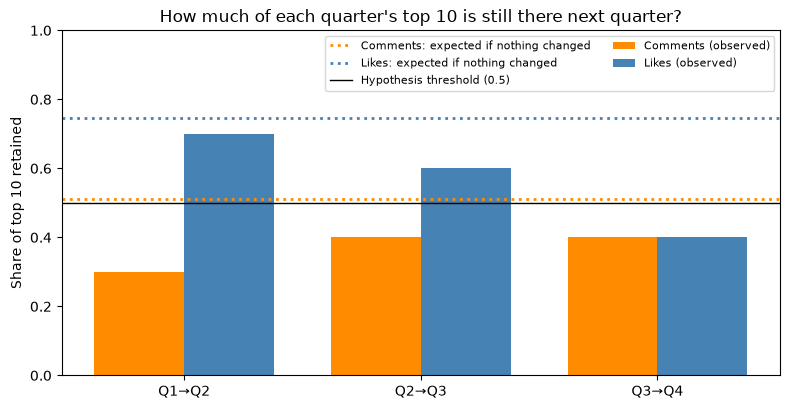

In [143]:
fig, ax = plt.subplots(figsize=(8, 4.2))
steps = ["Q1→Q2", "Q2→Q3", "Q3→Q4"]
x = np.arange(len(steps))
for i, (name, color) in enumerate([("Comments", "darkorange"), ("Likes", "steelblue")]):
    r = results[name]
    ax.bar(x + (i - 0.5) * 0.38, r["observed"], width=0.38, color=color, label=f"{name} (observed)")
    ax.axhline(r["shuffled"], color=color, linestyle=":", linewidth=2,
               label=f"{name}: expected if nothing changed")
ax.axhline(0.5, color="black", linewidth=1, label="Hypothesis threshold (0.5)")
ax.set_xticks(x, steps)
ax.set_ylim(0, 1)
ax.set_ylabel("Share of top 10 retained")
ax.set_title("How much of each quarter's top 10 is still there next quarter?")
ax.legend(fontsize=8, loc="upper right", ncol=2)
plt.tight_layout()
plt.show()

**Result.** For comments, mean retention is **0.37**: fewer than four of a quarter's top 10 stay in the next quarter's. That is below the 0.5 threshold and below the shuffled baseline (0.51; only 2.3% of shuffles were as low, p = 0.023). **Both conditions hold, so the hypothesis is supported.**

Likes are the comparison. Their retention (0.57) is *above* 0.5, so by the threshold alone they look stable. But with about 1,000 to 1,600 likes per quarter, unchanging interests would keep about 74% of the top 10, and no shuffle was as low as 0.57 (p < 0.001). Likes ebb and flow too, just less than comments, and their retention falls across the year (0.7, 0.6, 0.4).

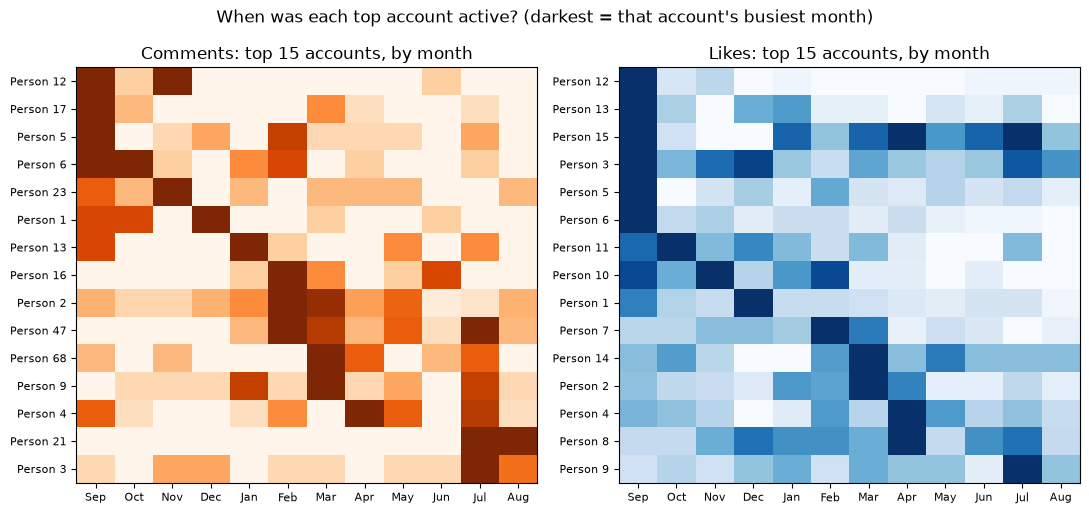

In [144]:
# Which months was each top account active in?
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, (name, data), cmap in zip(axes, [("Comments", df2), ("Likes", df)], ["Oranges", "Blues"]):
    d = data[data["account"].notna() & (data["datetime"] >= EDGES[0]) & (data["datetime"] < EDGES[-1].replace(day=1))]   # 12 whole months
    top = d["account"].value_counts().head(15).index
    monthly = (d[d["account"].isin(top)]
                 .groupby(["account", pd.Grouper(key="datetime", freq="MS")]).size()
                 .unstack(fill_value=0))
    monthly = monthly.div(monthly.max(axis=1), axis=0)                            # 1 = that account's busiest month
    monthly = monthly.loc[monthly.idxmax(axis=1).sort_values(kind="stable").index]  # rows ordered by busiest month
    ax.imshow(monthly, aspect="auto", cmap=cmap, vmin=0, vmax=1)
    ax.set_yticks(range(len(monthly)), monthly.index, fontsize=8)
    ax.set_xticks(range(len(monthly.columns)), [f"{m:%b}" for m in monthly.columns], fontsize=8)
    ax.set_title(f"{name}: top 15 accounts, by month")
fig.suptitle("When was each top account active? (darkest = that account's busiest month)")
plt.tight_layout()
plt.show()

Each row is one of the top 15 accounts and each column a month; the darkest square is that account's busiest month, and rows are sorted by it. A fixed circle would show solid stripes across the year. Instead, comments flare up for a month or two and fade, while likes keep a steadier core: the same contrast as the retention test. (Each row is scaled to its own busiest month; September was a heavy month for likes overall, so more accounts peak there.)

### Does the result depend on my choices?

The test above uses quarters and a top 10, chosen before running it. The cell below repeats it with 1-, 2- and 3-month periods and top 5, 10 and 20 cutoffs. Each entry is observed retention vs. the shuffled (chance) average, with its p-value (500 shuffles each).

In [145]:
def turnover_test(data, months, top, n_shuffles=500):
    """Mean retention of the top accounts between consecutive periods, vs. shuffled accounts."""
    edges = [EDGES[0] + pd.DateOffset(months=k) for k in range(0, 13, months)]
    period = pd.cut(data["datetime"], bins=edges, labels=False, right=False)
    keep = data["account"].notna() & period.notna()
    accounts, period = data.loc[keep, "account"].to_numpy(), period[keep].to_numpy()

    def mean_retention(acc):
        tops = [set(pd.Series(acc[period == p]).value_counts().head(top).index) for p in np.unique(period)]
        return np.mean([len(a & b) / top for a, b in zip(tops, tops[1:])])

    observed = mean_retention(accounts)
    shuffled = np.array([mean_retention(rng.permutation(accounts)) for _ in range(n_shuffles)])
    p = (shuffled <= observed).mean()
    return f"{observed:.2f} vs {shuffled.mean():.2f} (p {'< 0.002' if p == 0 else f'= {p:.3f}'})"

pd.DataFrame({name: {f"{m} month{'s' if m > 1 else ''}, top {t}" + ("  ← stated test" if (m, t) == (3, 10) else ""):
                     turnover_test(data, m, t)
                     for m in (3, 2, 1) for t in (5, 10, 20)}
              for name, data in [("Comments", df2), ("Likes", df)]})

,Comments,Likes
"3 months, top 5",0.40 vs 0.53 (p = 0.136),0.47 vs 0.76 (p < 0.002)
"3 months, top 10 ← stated test",0.37 vs 0.51 (p = 0.018),0.57 vs 0.75 (p < 0.002)
"3 months, top 20",0.43 vs 0.55 (p = 0.008),0.48 vs 0.74 (p < 0.002)
"2 months, top 5",0.48 vs 0.43 (p = 0.838),0.40 vs 0.65 (p = 0.002)
"2 months, top 10",0.38 vs 0.42 (p = 0.254),0.52 vs 0.68 (p = 0.006)
"2 months, top 20",0.33 vs 0.39 (p = 0.054),0.57 vs 0.66 (p = 0.006)
"1 month, top 5",0.33 vs 0.32 (p = 0.610),0.31 vs 0.50 (p < 0.002)
"1 month, top 10",0.25 vs 0.28 (p = 0.198),0.39 vs 0.55 (p < 0.002)
"1 month, top 20",0.21 vs 0.25 (p = 0.070),0.45 vs 0.52 (p < 0.002)


**Likes turn over faster than chance at every setting**, so that finding does not depend on my choices. **Comments do so only with 3-month periods and a top 10 or 20.** With shorter periods there are too few comments (35 to 138 a month) for real change to stand out, because chance alone already produces high turnover there. (The stated-test row differs slightly from the main test, p = 0.018 vs. 0.023, because it uses a new set of shuffles.)

This also exposes the weak half of my hypothesis: a fixed 0.5 threshold ignores that chance turnover depends on how much data each period has (chance retention ranges from 0.25 to 0.76 here). The comparison with chance is the better test.

## 11. Conclusions, limitations, next steps and disclosure

**Conclusions**
* Facebook exported my reactions twice, in two formats that agree to the second on 99% of records. Reconciled, the data is 5,039 reactions to 2,426 accounts in one year.
* My attention is spread thin (82% of accounts got a single reaction), and the leaders change over the year.
* My hypothesis, as stated (quarters, top 10), is supported for comments: fewer than half the top 10 carries over, which is more turnover than chance. But that comment result holds only at the quarterly scale. The more robust evidence is in my likes, which turn over faster than chance at every period and cutoff tested, even though they keep more than half their top 10. Either way, the accounts I interact with are a moving set, not a fixed circle.

**Limitations**
* Names are not IDs: two people with the same name merge, and a renamed account splits.
* The data cannot separate my changing interests from the algorithm changing what I see.
* Only three quarter-to-quarter comparisons, and the comment result depends on using quarters (see the robustness check). Ties at 10th place are broken arbitrarily, the same way in the shuffles.
* Records without an account (161 likes, 270 comments) are excluded, the two formats disagree on a few hundred records (section 5b), and removed reactions may not be exported at all.

**Alternative approaches and next steps**
* Request an "All time" export to test year-over-year change, with enough comments per period to test shorter periods reliably.
* Replace the top-10 cutoff with a rank correlation (Spearman) across all accounts.
* Use the new format's group field to see whether turnover follows the groups I join and leave, and the ads files to look for the algorithm's side of the feedback loop.

**Use of AI in this assignment**
* This data analysis is the result of a collaborative effort between Claude Opus 5.5 and me, with Claude doing most of the lifting and me doing most of the steering and editing. 